<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS10/lab1_js10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 — Import library

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from matplotlib.colors import ListedColormap

## Langkah 2 — Load data dan visualisasi
Dataset Iris terdiri atas 150 bunga, 4 fitur dan 3 spesies. Mengikuti modul, kita menggunakan 100 baris pertama untuk dua kelas: *setosa* dan *versicolor*.

In [2]:
if Path('iris.csv').exists():
    df = pd.read_csv('iris.csv', header=None)
    # Jika file iris.csv mempunyai header, gunakan fallback agar label yang dibaca tetap benar.
    if str(df.iloc[0, 4]) not in ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']:
        df = pd.read_csv('iris.csv', header=0)
        df.columns = range(5)
else:
    iris = load_iris()
    labels = ['Iris-' + iris.target_names[int(i)] for i in iris.target]
    df = pd.DataFrame(iris.data)
    df[4] = labels

setosa = df[df[4] == 'Iris-setosa']
versicolor = df[df[4] == 'Iris-versicolor']
virginica = df[df[4] == 'Iris-virginica']
print('Ukuran dataset:', df.shape)
print('Jumlah masing-masing kelas:')
print(df[4].value_counts())
display(df.head())

Ukuran dataset: (150, 5)
Jumlah masing-masing kelas:
4
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,0,1,2,3,4
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


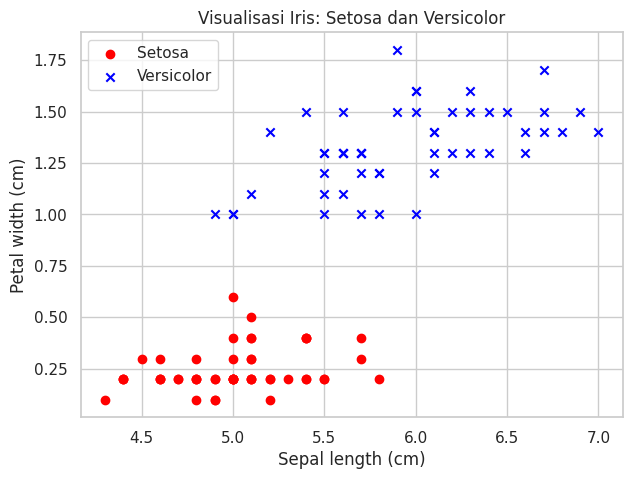

In [3]:
a, b = 0, 3  # 0 = sepal length, 3 = petal width
plt.figure(figsize=(7, 5))
plt.scatter(setosa[a], setosa[b], color='red', marker='o', label='Setosa')
plt.scatter(versicolor[a], versicolor[b], color='blue', marker='x', label='Versicolor')
plt.xlabel('Sepal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('Visualisasi Iris: Setosa dan Versicolor')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

## Langkah 3 — Membuat kelas Perceptron secara manual
Aturan update: `update = eta * (target - prediksi)`. Bobot dan bias diperbarui setiap terjadi kesalahan prediksi.

In [4]:
class Perceptron:
    def __init__(self, eta=0.01, n_iter=10):
        self.eta = eta
        self.n_iter = n_iter

    def fit(self, X, y):
        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []
        for _ in range(self.n_iter):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_[0] += update
                self.w_[1:] += update * xi
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

print('Kelas Perceptron berhasil dibuat.')

Kelas Perceptron berhasil dibuat.


## Langkah 4 — Memilih data dan encoding label
`Iris-setosa = -1` dan `Iris-versicolor = +1`. Mengikuti modul, dua fitur yang dipilih adalah kolom 0 dan 3.

In [5]:
# Pilih kedua kelas secara eksplisit agar tidak bergantung urutan baris CSV.
data_dua_kelas = df[df[4].isin(['Iris-setosa', 'Iris-versicolor'])].copy()
y = np.where(data_dua_kelas[4].to_numpy() == 'Iris-setosa', -1, 1)
X = data_dua_kelas[[0, 3]].to_numpy(dtype=float)
print('Bentuk X:', X.shape)
print('Distribusi label:', dict(zip(*np.unique(y, return_counts=True))))

Bentuk X: (100, 2)
Distribusi label: {np.int64(-1): np.int64(50), np.int64(1): np.int64(50)}


## Langkah 5 — Fitting model

In [6]:
ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)
prediksi = ppn.predict(X)
print('Bobot (bias, w1, w2):', ppn.w_)
print(f'Akurasi data latihan: {accuracy_score(y, prediksi):.2%}')
print('Kesalahan per epoch:', ppn.errors_)

Bobot (bias, w1, w2): [-0.4  -0.1   1.12]
Akurasi data latihan: 100.00%
Kesalahan per epoch: [2, 2, 2, 3, 2, 1, 0, 0, 0, 0]


## Langkah 6 — Visualisasi jumlah kesalahan per epoch

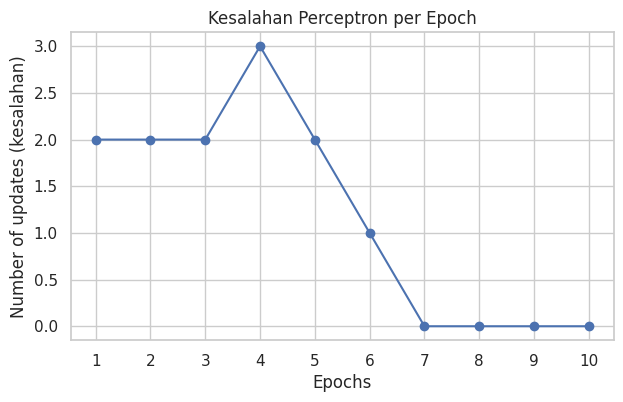

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Number of updates (kesalahan)')
plt.title('Kesalahan Perceptron per Epoch')
plt.xticks(range(1, len(ppn.errors_)+1))
plt.grid(True)
plt.show()

## Langkah 7 — Visualisasi decision boundary

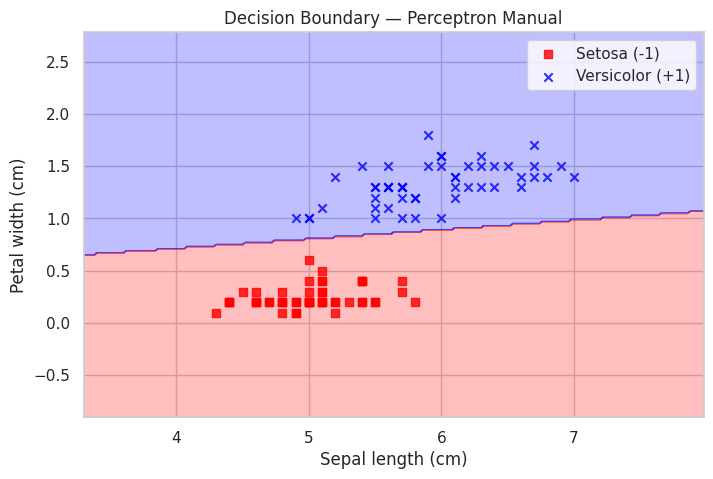

In [8]:
def plot_decision_regions(X, y, classifier, resolution=0.02):
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'green', 'black', 'gray')
    classes = np.unique(y)
    cmap = ListedColormap(colors[:len(classes)])

    x1_min, x1_max = X[:, 0].min()-1, X[:, 0].max()+1
    x2_min, x2_max = X[:, 1].min()-1, X[:, 1].max()+1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.25, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    for i, cl in enumerate(classes):
        plt.scatter(X[y == cl, 0], X[y == cl, 1],
                    color=colors[i], marker=markers[i], alpha=0.8,
                    label='Setosa (-1)' if cl == -1 else 'Versicolor (+1)')

plt.figure(figsize=(8, 5))
plot_decision_regions(X, y, classifier=ppn)
plt.xlabel('Sepal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('Decision Boundary — Perceptron Manual')
plt.legend(loc='best')
plt.show()

## Evaluasi dan kesimpulan

In [9]:
print('Confusion matrix:')
print(confusion_matrix(y, prediksi, labels=[-1, 1]))
print('\nClassification report:')
print(classification_report(y, prediksi, target_names=['Setosa', 'Versicolor'], zero_division=0))

Confusion matrix:
[[50  0]
 [ 0 50]]

Classification report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        50
  Versicolor       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



**Kesimpulan:** Perceptron adalah klasifikator linier. Pada fitur yang cukup memisahkan *setosa* dan *versicolor*, pembaruan bobot seharusnya semakin sedikit seiring proses pelatihan. Akurasi di atas merupakan akurasi pada **data pelatihan**, bukan pengujian pada data baru.